# PSM vs IPTW - ASMD

## Load Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.linear_model import LogisticRegression


In [2]:
df = pd.read_csv('analysis_ready.csv')
df = df[df['COMBINED_STAGE_GROUP'].isin([3, 4])]


#TACE first vs Systemic first
df_tace_sys = df[df['sequence_group'].isin([0, 1])].copy()

#TACE first vs Same-day
df_tace_same = df[df['sequence_group'].isin([0, 2])].copy()
df_tace_same['sequence_group'] = df_tace_same['sequence_group'].map({
    0: 0,
    2: 1  # same-day → new level 1
})

#Same-day vs Systemic first
df_same_sys = df[df['sequence_group'].isin([1, 2])].copy()
df_same_sys['sequence_group'] = df_same_sys['sequence_group'].map({
    2: 0,
    1: 1  # same-day → new level 1
})

covariates = [
    'AGE', 'SEX', 'RACE',
    'INSURANCE_STATUS',
    'Charlson_Deyo_Score', 'HISTOLOGY', 'COMBINED_STAGE_GROUP',
    'YEAR_OF_DIAGNOSIS', 'Surgery', 'Radiation_Therapy'
]

In [3]:
df_tace_sys.to_csv('df_tace_sys.csv', index=False)
df_tace_same.to_csv('df_tace_same.csv', index=False)
df_same_sys.to_csv('df_same_sys.csv', index=False)

In [4]:
df_same_sys['sequence_group'].value_counts(), df_tace_sys['sequence_group'].value_counts(), df_tace_same['sequence_group'].value_counts()

(sequence_group
 0    291
 1    205
 Name: count, dtype: int64,
 sequence_group
 0    930
 1    205
 Name: count, dtype: int64,
 sequence_group
 0    930
 1    291
 Name: count, dtype: int64)

## IPTW

In [5]:
def perform_iptw(df, covariates = covariates):
    
    df_encoded = pd.get_dummies(df[covariates], drop_first=True)
    X = df_encoded
    y = df['sequence_group']
    ps_model = LogisticRegression(max_iter=2000)
    ps_model.fit(X, y)
    df['ps'] = ps_model.predict_proba(X)[:, 1]
    
    df['iptw_weight'] = df.apply(
        lambda row: 1 / row['ps'] if row['sequence_group'] == 1 else 1 / (1 - row['ps']),
        axis=1
    )
    return df

df_tace_sys = perform_iptw(df_tace_sys)
df_tace_same = perform_iptw(df_tace_same)
df_same_sys = perform_iptw(df_same_sys)

## PSM

In [6]:
matched_tace_sys = pd.read_csv('matched_tace_sys.csv')
matched_tace_same = pd.read_csv('matched_tace_same.csv')
matched_same_sys = pd.read_csv('matched_same_sys.csv')

## AMSD plots

In [7]:
def compute_asmd(df, covariate, treatment_col, weight_col=None):
    groups = df[treatment_col].unique()
    g1 = df[df[treatment_col] == groups[0]]
    g2 = df[df[treatment_col] == groups[1]]

    if weight_col is None:
        w1 = np.ones(len(g1))
        w2 = np.ones(len(g2))
    else:
        w1 = g1[weight_col].values
        w2 = g2[weight_col].values

    def weighted_mean_std(x, w):
        mean = np.average(x, weights=w)
        var = np.average((x - mean)**2, weights=w)
        return mean, np.sqrt(var)

    if df[covariate].dtype in [np.float64, np.int64]:
        m1, s1 = weighted_mean_std(g1[covariate], w1)
        m2, s2 = weighted_mean_std(g2[covariate], w2)
        pooled_sd = np.sqrt((s1**2 + s2**2)/2)
        asmd = abs(m1 - m2) / pooled_sd
    else:
        # Categorical variable: use dummy encoding
        dummies = pd.get_dummies(df[covariate], drop_first=False)
        asmd_list = []
        for level in dummies.columns:
            x1 = dummies.loc[g1.index, level]
            x2 = dummies.loc[g2.index, level]
            m1 = np.average(x1, weights=w1)
            m2 = np.average(x2, weights=w2)
            pooled = (m1*(1 - m1) + m2*(1 - m2)) / 2
            asmd = abs(m1 - m2) / np.sqrt(pooled) if pooled > 0 else 0
            asmd_list.append(asmd)
        asmd = np.mean(asmd_list)
    return asmd

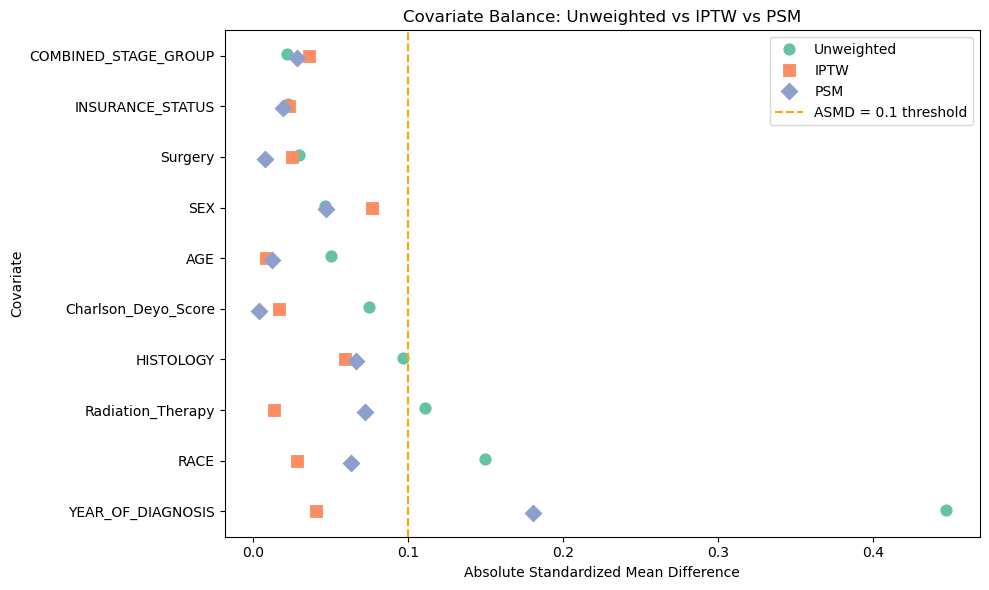

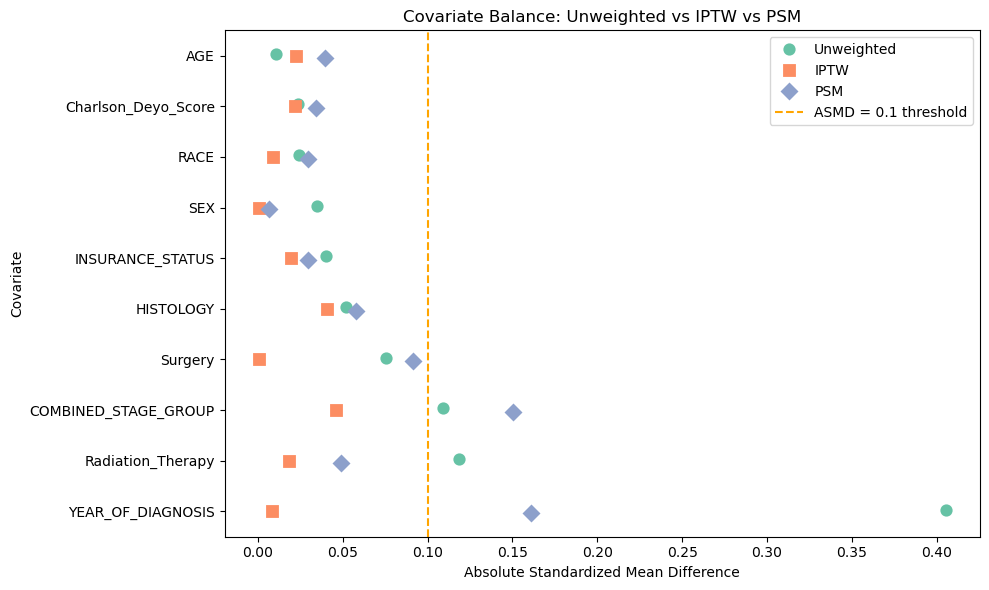

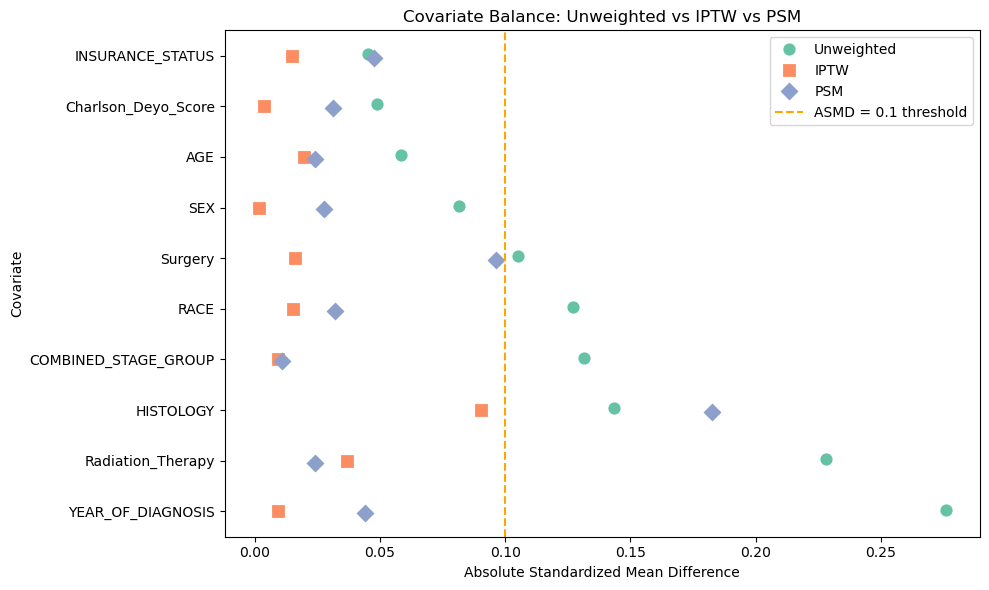

In [ ]:
df_dict = {
    'TACE fist vs Systemic first': [matched_tace_sys, df_tace_sys],
    'TACE fist vs Same-day': [matched_tace_same, df_tace_same],
    'Same-day vs Systemic first': [matched_same_sys, df_same_sys]
}


for comparison, df_pair in df_dict.items():
    asmd_unweighted = []
    asmd_weighted = []
    asmd_psm = []

    for covariate in covariates:
        try:
            a1 = compute_asmd(df_pair[1], covariate, 'sequence_group', weight_col=None)
            a2 = compute_asmd(df_pair[1], covariate, 'sequence_group', weight_col='iptw_weight')
            a3 = compute_asmd(df_pair[0], covariate, 'sequence_group', weight_col=None)
        except Exception as e:
            print(f"Skipping {covariate}: {e}")
            continue
        asmd_unweighted.append(a1)
        asmd_weighted.append(a2)
        asmd_psm.append(a3)


    asmd_df = pd.DataFrame({
        'Covariate': covariates,
        'Unweighted': asmd_unweighted,
        'IPTW': asmd_weighted,
        'PSM': asmd_psm
    })
    asmd_df.sort_values(by='Unweighted', ascending=True, inplace=True)

    asmd_df_melted = asmd_df.melt(id_vars='Covariate', var_name='Method', value_name='ASMD')

    plt.figure(figsize=(10, 6))
    sns.pointplot(
        data=asmd_df_melted,
        x='ASMD',
        y='Covariate',
        hue='Method',
        dodge=True,  # Separate points for each method
        linestyle='none',  # Do not connect points with lines
        markers=["o", "s", "D"],  # Optional: Different markers for clarity
        palette="Set2"  # Optional: Custom color palette
    )
    plt.axvline(0.1, linestyle='--', color='orange', label='ASMD = 0.1 threshold')
    plt.xlabel("Absolute Standardized Mean Difference")
    plt.title("Covariate Balance: Unweighted vs IPTW vs PSM")
    plt.legend(loc='upper right')
    plt.tight_layout()
    #plt.savefig(f'asmd_{comparison}.pdf', format='pdf', bbox_inches='tight')
    plt.show()